In [ ]:
!pip install python-dotenv huggingface-hub llama-index transformers sentence-transformers llama-index-llms-huggingface llama-index-embeddings-huggingface pdfplumber llama-index-llms-openrouter llama-index-retrievers-bm25 tabula-py  jpype1 pystemmer

## 1. Setup & Configuration
In this section, we set up the necessary dependencies, including third-party libraries and API keys.
We also configure the language models (LLMs) and embedding models used throughout the tutorial.

Key Steps:
- Import required Python libraries.
- Load API keys securely from environment variables.
- Initialize the OpenRouter LLMs for both querying and evaluation.
- Set up the HuggingFace embedding model for text representation.
- Apply `nest_asyncio` to handle event loop issues in Jupyter environments.


In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3" # Suppresses TensorFlow warnings
from dotenv import load_dotenv
import Stemmer
import nest_asyncio
import tabula
import pandas as pd
from dotenv import load_dotenv
from llama_index.core import Document
from llama_index.core import (SimpleDirectoryReader, VectorStoreIndex, Settings)
from llama_index.embeddings.huggingface import HuggingFaceEmbedding
from llama_index.llms.openrouter import OpenRouter
import asyncio


load_dotenv()  # reads OPENROUTER_API_KEY from a local .env file (never commit it)
api_key = os.getenv("OPENROUTER_API_KEY")
if not api_key:
    raise ValueError("OPENROUTER_API_KEY not found. Copy .env.example to .env and add your key.")


# Initialize OpenRouter LLM
#llm = OpenRouter(api_key=api_key, model="mistralai/mistral-7b-instruct", max_tokens=512, context_window=4096)
llm = OpenRouter(api_key=api_key, model="meta-llama/Llama-3.1-8B-Instruct", max_tokens=512, context_window=4096)
Judge_llm = OpenRouter(api_key=api_key, model="qwen/qwen-turbo", max_tokens=512, context_window=4096)
Settings.llm = llm

# Apply nest_asyncio to fix event loop issues in Jupyter
nest_asyncio.apply()

# Set up embedding model
embed_model_name = "sentence-transformers/all-MiniLM-L6-v2"
embed_model = HuggingFaceEmbedding(model_name=embed_model_name)
Settings.embed_model = embed_model

## 2. Document Loading & Preprocessing
Here, we load the syllabus document from a PDF file and process it for retrieval.

Key Steps:
- Read the syllabus PDF and extract its textual content.
- Extract tabular data from the PDF using `tabula`.
- Convert the extracted table data into text format.
- Combine the extracted text and tables into a unified document.
- Define an ingestion pipeline to preprocess text by splitting it into manageable chunks and applying embeddings.


In [2]:
import warnings
import logging

warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.ERROR)

# Common noisy libraries
for name in [
    "llama_index",
    "httpx",
    "httpcore",
    "openai",
    "urllib3",
    "tabula",
    "py4j",
]:
    logging.getLogger(name).setLevel(logging.ERROR)

In [5]:
import re
from llama_index.core import Document

# Load Course Syllabus Document
#pdf_path = "./Syllabus.pdf"
pdf_path = "./WebMD.pdf"
documents = SimpleDirectoryReader(input_files=[pdf_path]).load_data()

# Convert table data into an additional Document
tables = tabula.read_pdf(pdf_path, pages="all", force_subprocess=True)
table_docs = [df.to_markdown(index=False) for df in tables]
all_tables_text = "\n\n".join(table_docs)
document_from_tables = Document(text=all_tables_text)

documents = documents + [document_from_tables]

# PDF TEXT CLEANING STEP (Task 1 - Structure Handling)
def clean_pdf_text(t: str) -> str:
    t = re.sub(r"/gid\d+", "", t) 
    t = re.sub(r"(\w)-\s*\n(\w)", r"\1\2", t) 
    t = re.sub(r"\n{3,}", "\n\n", t) 
    t = re.sub(r"[ \t]{2,}", " ", t) 
    return t.strip()

print("BEFORE CLEANING:\n")
print(documents[0].text[:600])

documents = [
    Document(text=clean_pdf_text(d.text), metadata=d.metadata)
    for d in documents
]

print("\nAFTER CLEANING:\n")
print(documents[0].text[:600])

# pipeline with transformations
from llama_index.core.node_parser import SentenceSplitter, TokenTextSplitter
from llama_index.core.ingestion import IngestionPipeline

#pipeline = IngestionPipeline(transformations=[SentenceSplitter(chunk_size=128, chunk_overlap=0), embed_model])
pipeline = IngestionPipeline(
    transformations=[
        TokenTextSplitter(
            separator="\n\n",
            chunk_size=512,
            chunk_overlap=100
        ),
        embed_model
    ]
)
# Run the pipeline
nodes = pipeline.run(documents=documents)

BEFORE CLEANING:

/gid00019/gid00006/gid00002/gid00013 /gid00020/gid00021/gid00016/gid00019/gid00010/gid00006/gid00020
CHRONIC MIGRAINE
/gid00009/gid00006/gid00002/gid00013 /gid00021/gid00009/gid00001/gid00020/gid00014/gid00002/gid00019/gid00021/gid00020
/gid00002/gid00001/gid00039/gid00042/gid00042/gid00038/gid00001/gid00036/gid00041/gid00046/gid00036/gid00031/gid00032/gid00001/gid00001
/gid00052/gid00042/gid00048/gid00045/gid00001/gid00035/gid00032/gid00028/gid00031/gid00001/gid00001
/gid00028/gid00041/gid00031/gid00001/gid00040/gid00042/gid00045/gid00032
/gid00043/gid00028/gid00034/gid00032/gid00001/gid01109

AFTER CLEANING:

CHRONIC MIGRAINE
 

 

COMPLIMENTARY COPY
TAKE ONE HOME
SCAN ME
Watch this video on one woman’s 
journey living with chronic 
migraine. For more on her 
story, turn to page 14. Use your 
smartphone camera to activate 
the QR code.


## 3. Indexing & Retrieval
Once the document is processed, we create multiple retrievers for efficient information retrieval.

Key Steps:
- Build a `VectorStoreIndex` from the preprocessed document chunks.
- Implement different retrieval methods:
  - **Base Retriever:** Retrieves the most relevant document chunk.
  - **AutoMerging Retriever:** Aggregates multiple related chunks before returning results.
  - **BM25 Retriever:** Uses term frequency-based ranking (a traditional information retrieval method).
  - **Hybrid Fusion Retriever:** (Task 4)
- Define retrieval hyperparameters, such as similarity threshold and number of top results to return.


In [7]:
# Vector Index and Query Engine
index = VectorStoreIndex(nodes)
query_engine = index.as_query_engine()

base_retriever = index.as_retriever(similarity_top_k=1)

from llama_index.core.retrievers import AutoMergingRetriever
auto_base_retriever = index.as_retriever(similarity_top_k=3)
auto_merging_retriever = AutoMergingRetriever(auto_base_retriever, index.storage_context)

from llama_index.retrievers.bm25 import BM25Retriever
bm25_retriever = BM25Retriever.from_defaults(nodes=nodes, similarity_top_k=2, stemmer=Stemmer.Stemmer("english"), language="english")

# Create Hybrid Fusion Retriever (Task 4)
from llama_index.core.retrievers import QueryFusionRetriever

vector_retriever_fusion = index.as_retriever(similarity_top_k=8)
bm25_retriever_fusion = BM25Retriever.from_defaults(
    nodes=nodes,
    similarity_top_k=8,
    stemmer=Stemmer.Stemmer("english"),
    language="english"
)

fusion_retriever = QueryFusionRetriever(
    retrievers=[vector_retriever_fusion, bm25_retriever_fusion],
    retriever_weights=[0.6, 0.4],
    similarity_top_k=5,   
    num_queries=1       
)

## 4. Query Engines & Evaluation Setup
In this section, we configure the query engines and set up evaluation metrics to assess retriever performance.

Key Steps:
- Instantiate query engines for each retrieval method to allow direct querying.
- Define evaluation models to measure:
  - **Faithfulness:** Whether the retrieved information is accurate and grounded in the original document.
  - **Relevancy:** Whether the retrieved information is relevant to the query.
- Configure different retriever evaluators to assess retrieval effectiveness using metrics such as:
  - Mean Reciprocal Rank (MRR)
  - Hit Rate
  - Precision
  - Recall


In [8]:
from llama_index.core.query_engine import RetrieverQueryEngine
from llama_index.core.evaluation import FaithfulnessEvaluator, RelevancyEvaluator, RetrieverEvaluator

base_query_engine = RetrieverQueryEngine.from_args(base_retriever)
auto_query_engine = RetrieverQueryEngine.from_args(auto_merging_retriever)
bm25_query_engine = RetrieverQueryEngine.from_args(bm25_retriever)

faithfulness_evaluator = FaithfulnessEvaluator(llm=Judge_llm)
relevancy_evaluator = RelevancyEvaluator(llm=Judge_llm)

base_retriever_evaluator = RetrieverEvaluator.from_metric_names(["mrr", "hit_rate", "precision", "recall"], retriever=base_retriever)
auto_retriever_evaluator = RetrieverEvaluator.from_metric_names(["mrr", "hit_rate", "precision", "recall"], retriever=auto_merging_retriever)
bm25_retriever_evaluator = RetrieverEvaluator.from_metric_names(["mrr", "hit_rate", "precision", "recall"], retriever=bm25_retriever)

## 5. Preparing Evaluation Questions & Display Functions

In this section, we define a set of evaluation questions to systematically assess the performance of different retrieval methods. Additionally, we create utility functions for displaying results in a structured and readable format.

Key Steps:
- Define a set of test queries (e.g., syllabus-related questions).
- Generate question-context pairs for automated evaluation.

To make evaluation results more interpretable, we define:
- **`displayify_df(df)`**: A helper function to format and display DataFrames neatly in Jupyter notebooks.
- **`display_retriever_eval_results(name, eval_results)`**: Computes and prints key retrieval evaluation metrics.

In [11]:
from llama_index.core.evaluation import QueryResponseDataset, generate_question_context_pairs, EmbeddingQAFinetuneDataset
# Use Evaluation Questions
#eval_questions = []
#with open('eval_questions.txt', 'r') as file:
# for line in file:
 # eval_questions.append(line.strip())

# Add more evaluation questions
#eval_questions = [
 # "How can a student request a regrade?",
  # "What topic is covered in Week 3?",
   # "What's happening on Feb 17?"
#]

eval_questions = [
    "What are common symptoms of chronic migraine?",
    "What treatments are mentioned for chronic migraine?",
    "What are possible triggers or risk factors discussed?"
]

qa_dataset = generate_question_context_pairs(nodes=nodes, llm=llm, num_questions_per_chunk=1)
qa_dataset.save_json("qa_dataset_webmd_new.json")

#qa_dataset = QueryResponseDataset.from_json("./qa_dataset_webmd_new.json")
#qa_dataset = EmbeddingQAFinetuneDataset.from_json("./qa_dataset_webmd_new.json")

# Pretty Display Function
def displayify_df(df):
    """For pretty displaying DataFrame in a notebook."""
    display_df = df.style.set_properties(
        **{
            "inline-size": "300px",
            "overflow-wrap": "break-word",
        }
    )
    display(display_df)

# Helper to display retrieval metrics
def display_retriever_eval_results(name, eval_results):
    """Build a small DataFrame summarizing retrieval metrics across queries."""
    print(f"=== {name} ===")
    metric_dicts = [res.metric_vals_dict for res in eval_results]
    if not metric_dicts:
        print("No retriever metrics found!")
        return
    df = pd.DataFrame(metric_dicts)
    #displayify_df(df)
    print("Mean:\n", df.mean(numeric_only=True), "\n")

## 6. Running Evaluations & Comparing Retrievers
Finally, we conduct retrieval evaluations and compare the effectiveness of different retrieval strategies.

Key Steps:
- Execute retrieval on all retrievers (Base, AutoMerging, BM25, Hybrid Fusion).
- Assess each retriever's faithfulness and relevancy scores.
- Compare retrieval results by averaging the evaluation metrics.
- Display results in tabular format for easy comparison.

This step helps determine which retrieval method performs best for a given dataset.


In [12]:
import asyncio

# Modify Evaluation to Include Fusion Retriever
async def run_evaluation():
    eval_results = []

    for query in eval_questions:
        # Retrieve responses from all four retrievers
        base_response = base_query_engine.query(query)
        auto_response = auto_query_engine.query(query)
        bm25_response = bm25_query_engine.query(query)

        base_text = base_response.response
        auto_text = auto_response.response
        bm25_text = bm25_response.response

        base_contexts = "\n".join([node.get_content() for node in base_response.source_nodes])
        auto_contexts = "\n".join([node.get_content() for node in auto_response.source_nodes])
        bm25_contexts = "\n".join([node.get_content() for node in bm25_response.source_nodes])

        # Evaluate Faithfulness & Relevancy for each retriever
        base_faithfulness = faithfulness_evaluator.evaluate_response(response=base_response)
        auto_faithfulness = faithfulness_evaluator.evaluate_response(response=auto_response)
        bm25_faithfulness = faithfulness_evaluator.evaluate_response(response=bm25_response)

        base_relevancy = relevancy_evaluator.evaluate_response(query=query, response=base_response)
        auto_relevancy = relevancy_evaluator.evaluate_response(query=query, response=auto_response)
        bm25_relevancy = relevancy_evaluator.evaluate_response(query=query, response=bm25_response)

        eval_results.append({
            "Query": query,
            "Base Response": base_text,
            "Auto-Merged Response": auto_text,
            "BM25 Response": bm25_text,
            "Base Context": "".join(base_contexts[:100]) + "... " + "".join(base_contexts[-100:]),
            "Auto Context": "".join(auto_contexts[:100]) + "... " + "".join(auto_contexts[-100:]),
            "BM25 Context": "".join(bm25_contexts[:100]) + "... " + "".join(bm25_contexts[-100:]),
            "Base Faithfulness": base_faithfulness.score,
            "Auto Faithfulness": auto_faithfulness.score,
            "BM25 Faithfulness": bm25_faithfulness.score,
            "Base Relevancy": base_relevancy.score,
            "Auto Relevancy": auto_relevancy.score,
            "BM25 Relevancy": bm25_relevancy.score,
        })

    df = pd.DataFrame(eval_results)

    # Compute means for comparison
    print("\nFaithfulness Comparison")
    print(f"Base Retriever: {df['Base Faithfulness'].mean():.4f}")
    print(f"Auto-Merging Retriever: {df['Auto Faithfulness'].mean():.4f}")
    print(f"BM25 Retriever: {df['BM25 Faithfulness'].mean():.4f}")

    print("\nRelevancy Comparison")
    print(f"Base Retriever: {df['Base Relevancy'].mean():.4f}")
    print(f"Auto-Merging Retriever: {df['Auto Relevancy'].mean():.4f}")
    print(f"BM25 Retriever: {df['BM25 Relevancy'].mean():.4f}")

    # Evaluate all retrievers on the QA dataset
    base_eval_results = await base_retriever_evaluator.aevaluate_dataset(qa_dataset)
    auto_eval_results = await auto_retriever_evaluator.aevaluate_dataset(qa_dataset)
    bm25_eval_results = await bm25_retriever_evaluator.aevaluate_dataset(qa_dataset)

    print("=== Retrieval Metrics Comparison ===")
    display_retriever_eval_results("Base Retriever", base_eval_results)
    display_retriever_eval_results("Auto-Merging Retriever", auto_eval_results)
    display_retriever_eval_results("BM25 Retriever", bm25_eval_results)

    # Display results table
    displayify_df(df)

# Execute Async Evaluation
#asyncio.run(run_evaluation())
await run_evaluation()


Faithfulness Comparison
Base Retriever: 1.0000
Auto-Merging Retriever: 1.0000
BM25 Retriever: 1.0000

Relevancy Comparison
Base Retriever: 0.6667
Auto-Merging Retriever: 1.0000
BM25 Retriever: 0.3333
=== Retrieval Metrics Comparison ===
=== Base Retriever ===
Mean:
 mrr          0.058824
hit_rate     0.058824
precision    0.058824
recall       0.058824
dtype: float64 

=== Auto-Merging Retriever ===
Mean:
 mrr          0.137255
hit_rate     0.235294
precision    0.078431
recall       0.235294
dtype: float64 

=== BM25 Retriever ===
Mean:
 mrr          0.058824
hit_rate     0.117647
precision    0.058824
recall       0.117647
dtype: float64 



,Query,Base Response,Auto-Merged Response,BM25 Response,Base Context,Auto Context,BM25 Context,Base Faithfulness,Auto Faithfulness,BM25 Faithfulness,Base Relevancy,Auto Relevancy,BM25 Relevancy
0,What are common symptoms of chronic migraine?,"The text doesn't explicitly mention the common symptoms of chronic migraine. However, it does describe the author's experience with migraines as a ""chronic and debilitating condition"" that doesn't just go away, suggesting that it has a significant impact on their daily life.","People who experience chronic migraine are more likely to have poor sleep quality and duration, as well as sleep disorders such as sleep apnea, insomnia, and restless legs syndrome. They may also be at a higher risk of having mood disorders, including depression and anxiety, with odds ranging between 30% and 50%. Additionally, they may experience gastrointestinal issues, such as nausea and diarrhea.","Based on the information provided, the common symptoms of migraines are: • Nausea • Vomiting • Photophobia • Phonophobia","13THIS CONTENT IS CREATED AND CONTROLLED BY WEBMD’S EDITORIAL STAFF | WWW.WEBMD.COM JACOB WACKERHA... like I do my patients, with compas - sion and love. These days, I treat myself like my best friend.","13THIS CONTENT IS CREATED AND CONTROLLED BY WEBMD’S EDITORIAL STAFF | WWW.WEBMD.COM JACOB WACKERHA... ses Dominguez, MD, an assistant professor of neurology at Weill Cornell Medicine in New York City.","Important Facts about VYEPTI® (vye-ep’-tee) injection for intravenous use, also known as eptinezumab... e 30 minutes to 7 days N/A • No nausea or vomiting, • No more than one of photophobia or phonophobia",1.000000,1.000000,1.000000,0.000000,1.000000,0.000000
1,What treatments are mentioned for chronic migraine?,Medicine for relief during an attack and medicine to prevent future attacks.,"Over-the-counter or prescription pain relievers, nerve stimulation, biofeedback, transcranial magnetic stimulation, acupuncture, CGRP antibody drugs, and botulinum toxin injection.","Nerve stimulation, biofeedback, transcranial magnetic stimulation, and acupuncture are some nondrug options that might help with chronic migraine.","THIS CONTENT IS CREATED AND CONTROLLED BY WEBMD’S EDITORIAL STAFF | WWW.WEBMD.COM 11 hen you have c... ses Dominguez, MD, an assistant professor of neurology at Weill Cornell Medicine in New York City.","THIS CONTENT IS CREATED AND CONTROLLED BY WEBMD’S EDITORIAL STAFF | WWW.WEBMD.COM 11 hen you have c... like I do my patients, with compas - sion and love. These days, I treat myself like my best friend.",Some nondrug options might also help with chronic migraine. Ask your doctor about nerve stimulation... your breast milk. Ӯ Y ou are under . It is not gnotn if VYEPTI is safe and effective in children.,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
2,What are possible triggers or risk factors discussed?,"Possible triggers or risk factors include having more days a month with migraine, sleep apnea, insomnia, restless legs syndrome, poor sleep quality and duration, having aura, cardiovascular disease, arthritis, epilepsy, multiple sclerosis, stroke, fibromyalgia, and gastrointestinal issues such as nausea and diarrhea.","Changes in barometric pressure, poor sleep quality, poor sleep duration, insomnia, restless legs syndrome, stress, low energy, high energy, fibromyalgia, nausea, diarrhea, pregnancy, breastfeeding, and certain medications.","Changes in barometric pressure, poor sleep, poor sleep the night before, low energy the day before, stress, and significantly higher-than-usual energy levels are possible triggers or risk factors discussed.","REAL STORIES | CHRONIC MIGRAINE | WINTER 202510 MOOD DISORDERS Your chance of having depression ... GASTRO ISSUES GI issues often go along with migraine. It’s common to deal with nausea, diarrhea,",REAL STORIES | CHRONIC MIGRAINE | WINTER 202510 MOOD DISORDERS Your chance of having depression ... UIDES-StandardFullPage.indd 1GUIDES-Standar

In [13]:
import pandas as pd

results = pd.DataFrame([
    # ---------- Baseline: 256 / 0 ----------
    {"setting":"Baseline (256/0)", "retriever":"Base",        "mrr":0.016393, "hit_rate":0.016393, "precision":0.016393, "recall":0.016393, "faithfulness":0.6667, "relevancy":0.3333},
    {"setting":"Baseline (256/0)", "retriever":"Auto-Merging","mrr":0.021858, "hit_rate":0.032787, "precision":0.010929, "recall":0.032787, "faithfulness":0.6667, "relevancy":0.6667},
    {"setting":"Baseline (256/0)", "retriever":"BM25",        "mrr":0.024590, "hit_rate":0.032787, "precision":0.016393, "recall":0.032787, "faithfulness":1.0000, "relevancy":0.3333},

    # ---------- Optimized: 512 / 100 ----------
    {"setting":"Optimized (512/100)", "retriever":"Base",        "mrr":0.058824, "hit_rate":0.058824, "precision":0.058824, "recall":0.058824, "faithfulness":1.0000, "relevancy":0.6667},
    {"setting":"Optimized (512/100)", "retriever":"Auto-Merging","mrr":0.137255, "hit_rate":0.235294, "precision":0.078431, "recall":0.235294, "faithfulness":1.0000, "relevancy":1.0000},
    {"setting":"Optimized (512/100)", "retriever":"BM25",        "mrr":0.058824, "hit_rate":0.117647, "precision":0.058824, "recall":0.117647, "faithfulness":1.0000, "relevancy":0.3333},
])

results

,setting,retriever,mrr,hit_rate,precision,recall,faithfulness,relevancy
0,Baseline (256/0),Base,0.016393,0.016393,0.016393,0.016393,0.6667,0.3333
1,Baseline (256/0),Auto-Merging,0.021858,0.032787,0.010929,0.032787,0.6667,0.6667
2,Baseline (256/0),BM25,0.024590,0.032787,0.016393,0.032787,1.0000,0.3333
3,Optimized (512/100),Base,0.058824,0.058824,0.058824,0.058824,1.0000,0.6667
4,Optimized (512/100),Auto-Merging,0.137255,0.235294,0.078431,0.235294,1.0000,1.0000
5,Optimized (512/100),BM25,0.058824,0.117647,0.058824,0.117647,1.0000,0.3333


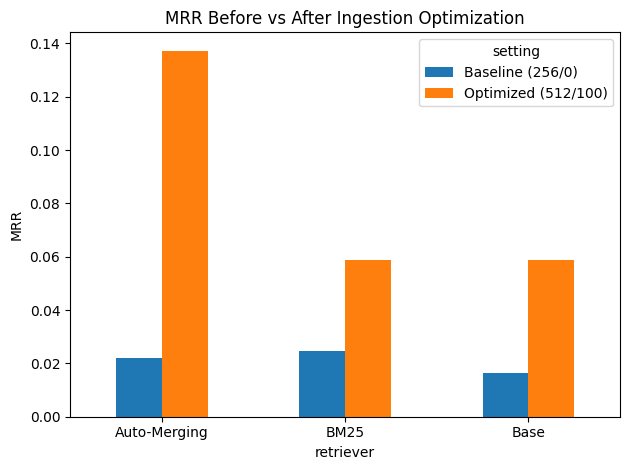

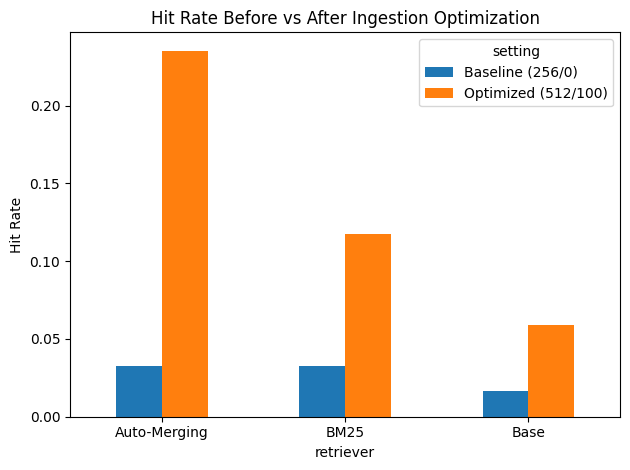

In [14]:
import matplotlib.pyplot as plt

pivot_mrr = results.pivot(index="retriever", columns="setting", values="mrr")

ax = pivot_mrr.plot(kind="bar", rot=0)
ax.set_title("MRR Before vs After Ingestion Optimization")
ax.set_ylabel("MRR")
plt.tight_layout()
plt.show()

pivot_hit = results.pivot(index="retriever", columns="setting", values="hit_rate")

ax = pivot_hit.plot(kind="bar", rot=0)
ax.set_title("Hit Rate Before vs After Ingestion Optimization")
ax.set_ylabel("Hit Rate")
plt.tight_layout()
plt.show()